# Bergman Glucose-Insulin Minimal Model for Type 1 Diabetes with a Hybrid Universal Neural ODE

**Course project - Mathematical Modelling**

We model how blood glucose responds to meals and insulin in people with Type 1 diabetes.

1. **Data** — real continuous glucose monitoring (CGM), insulin and meal records from the HUPA-UCM dataset (Hidalgo et al., *Data in Brief* 55, 2024).
2. **Mechanistic model** — the Bergman minimal model adapted to Type 1 diabetes (no pancreatic insulin secretion), with subcutaneous insulin absorption and a gut compartment.
3. **Analysis** — steady state, local stability, parameter identifiability, local and global (Sobol) sensitivity.
4. **Hybrid universal differential equation (UDE)** — neural networks replace the fixed gut absorption rates inside the ODE; the rest of the physiology is kept.
5. **Validation** — (a) on simulated patients from the FDA-accepted UVA/Padova simulator, where the true absorption is known; (b) out-of-sample forecasting on held-out days and on patients never seen in training, against a persistence baseline and an LSTM.

Run the notebook top to bottom from inside the `notebook/` folder. Trained models are saved in `models/`; set `RETRAIN = True` in the setup cell to retrain everything from scratch (≈ 15–20 min on a laptop CPU).

In [ ]:
import warnings, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pathlib import Path

warnings.filterwarnings("ignore")
RETRAIN = False          # True = refit/retrain every model instead of loading saved ones
SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_default_dtype(torch.float64)

ROOT  = Path("..")                       # notebook lives in notebook/
DATA  = ROOT / "data" / "hupa_ucm"
SIM   = ROOT / "data" / "simulated"
PROC  = ROOT / "data" / "processed"
MODEL = ROOT / "models"
FIG   = ROOT / "report" / "figures"
for p in (PROC, MODEL, FIG):
    p.mkdir(parents=True, exist_ok=True)

C_MODEL, C_HYB, C_LSTM, C_PERS, C_OBS, C_MEAL = "#1f4e79", "#c00000", "#548235", "#7f7f7f", "#000000", "#c55a11"
plt.rcParams.update({"figure.figsize": (6.5, 3.2), "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

def save_fig(fig, name):
    """Every report figure goes through here: EPS for the LaTeX report, PNG for viewing.
    Solid colours only: EPS has no transparency."""
    fig.savefig(FIG / f"{name}.eps", format="eps", bbox_inches="tight")
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Data: loading, units and cleaning

<div style="background:linear-gradient(90deg,#1f4e79,#2e75b6);color:white;padding:10px 14px;border-radius:6px;font-size:1.25em;font-weight:600">1. Data: loading, units and cleaning</div>

Each CSV has one row every 5 minutes: `glucose` (mg/dL), `basal_rate` and `bolus_volume_delivered` (insulin), `carb_input`, plus wearable signals we do not use.

**What we found when profiling all 25 files** (table below):

* **Carbohydrate units differ between patients.** Most patients log values 0.5–13 in half-steps: these are Spanish carbohydrate *raciones* (1 ración = 10 g). Patients 0002, 0004 and 0022 log 55–130, i.e. grams. Rule used: median logged value ≥ 20 → grams, otherwise × 10 g.
* **Insulin.** `basal_rate` is the insulin (U) delivered in each 5-min step (it sums to 6–39 U/day, a plausible basal total); boluses are in U.
* **Excluded patients:** no insulin at all (0011, 0015, 0018), no basal record (0014), no meals (0015, 0018, 0020), meals and boluses logged only as constant 1-markers without amounts (0019, 0021), glucose that is more than half straight-line gap fills (0009, 0010), and too few usable meal windows to fit five parameters (0026).
* **Long records** (0026: 141 days, 0027: 574 days, 0028: 90 days) are cut to the 30-day block with the best basal-insulin coverage, so they do not dominate training.
* **Glucose is a 15-min sensor (FreeStyle Libre 2) linearly interpolated to 5 min.** Short interpolations are fine; but long straight-line stretches (≥ 30 min) are filled sensor gaps, and readings ≤ 40 mg/dL are the sensor floor. Both are kept in the data but **masked out of every loss and error metric**.

In [ ]:
EXCLUDE = {"HUPA0011P": "no insulin", "HUPA0014P": "no basal record", "HUPA0015P": "no insulin, no meals",
           "HUPA0018P": "no insulin, no meals", "HUPA0020P": "no meals",
           "HUPA0019P": "meals/boluses only as 1-markers", "HUPA0021P": "meals/boluses only as 1-markers"}
MAX_DAYS = 30

def gap_mask(g, min_len=6, tol=0.05):
    """True where glucose lies on a straight line for >= min_len consecutive steps (filled sensor gap)."""
    d2 = np.abs(np.diff(g, 2)) < tol
    flag = np.zeros(len(g), bool)
    run = 0
    for k, z in enumerate(d2):
        run = run + 1 if z else 0
        if run >= min_len:
            flag[k - run + 1: k + 3] = True
    return flag

def load_patient(path):
    df = pd.read_csv(path, sep=";", parse_dates=["time"]).set_index("time").asfreq("5min")
    if len(df) > MAX_DAYS * 288:                           # long record: best-covered 30-day block
        cover = (df["basal_rate"] > 0).astype(float).rolling(MAX_DAYS * 288).mean().values
        end = int(np.nanargmax(cover)) + 1
        df = df.iloc[end - MAX_DAYS * 288: end]
    raw = df["carb_input"].fillna(0)
    grams = raw[raw > 0].median() >= 20
    df["carbs_g"]   = raw * (1.0 if grams else 10.0)
    df["insulin_U"] = df["basal_rate"].fillna(0) + df["bolus_volume_delivered"].fillna(0)
    g = df["glucose"].values.astype(float)
    df["gapfill"] = gap_mask(g)
    df["clipped"] = g <= 40
    df["valid"]   = ~(df["gapfill"] | df["clipped"] | np.isnan(g))
    df.attrs["carb_unit"] = "g" if grams else "10 g"
    return df

files = sorted(DATA.glob("HUPA*.csv"))
patients = {f.stem: load_patient(f) for f in files if f.stem not in EXCLUDE}
for pid in list(patients):                       # sensor data mostly straight-line gap fills
    if (~patients[pid]["valid"]).mean() > 0.5:
        EXCLUDE[pid] = f"{100*(~patients[pid]['valid']).mean():.0f}% of glucose is gap-filled"
        del patients[pid]

rows = []
for f in files:
    pid = f.stem
    if pid in EXCLUDE:
        rows.append({"patient": pid, "used": "no", "reason": EXCLUDE[pid]}); continue
    d = patients[pid]; days = len(d) / 288
    rows.append({"patient": pid, "used": "yes", "days": round(days, 1),
                 "carb unit": d.attrs["carb_unit"], "meals/day": round((d["carbs_g"] > 0).sum() / days, 1),
                 "insulin U/day": round(d["insulin_U"].sum() / days, 1),
                 "mean glucose": round(d["glucose"].mean()), "masked %": round(100 * (~d["valid"]).mean(), 1)})
cohort = pd.DataFrame(rows).set_index("patient")
cohort.to_csv(PROC / "cohort_summary.csv")
print(f"{len(patients)} patients used, {len(EXCLUDE)} excluded")
cohort

16 patients used, 9 excluded


,used,days,carb unit,meals/day,insulin U/day,mean glucose,masked %,reason
patient,,,,,,,,
HUPA0001P,yes,14.2,10 g,2.8,25.4,181.0,2.4,NaN
HUPA0002P,yes,11.0,g,1.1,46.5,113.0,8.5,NaN
HUPA0003P,yes,13.1,10 g,5.0,36.2,143.0,1.8,NaN
HUPA0004P,yes,11.1,g,1.8,64.0,180.0,16.5,NaN
HUPA0005P,yes,13.4,10 g,4.1,26.7,148.0,2.1,NaN
HUPA0006P,yes,8.0,10 g,4.7,50.2,165.0,5.6,NaN
HUPA0007P,yes,13.4,10 g,6.1,58.4,173.0,2.2,NaN
HUPA0009P,no,NaN,NaN,NaN,NaN,NaN,NaN,100% of glucose is gap-filled
HUPA0010P,no,NaN,NaN,NaN,NaN,NaN,NaN,90% of glucose is gap-filled


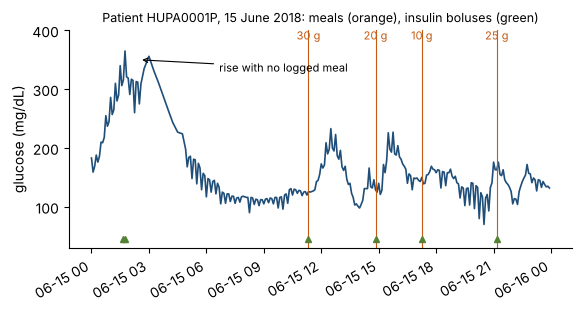

In [ ]:
d = patients["HUPA0001P"].loc["2018-06-15"]
fig, ax = plt.subplots()
ax.plot(d.index, d["glucose"], color=C_MODEL, lw=1.2)
ymax = 380
for t, c in d.loc[d["carbs_g"] > 0, "carbs_g"].items():
    ax.axvline(t, color=C_MEAL, lw=0.8)
    ax.text(t, ymax, f"{c:.0f} g", color=C_MEAL, fontsize=8, ha="center", va="bottom")
for t, u in d.loc[d["bolus_volume_delivered"] > 0, "bolus_volume_delivered"].items():
    ax.plot(t, 45, marker="^", color=C_LSTM, ms=5)
ax.annotate("rise with no logged meal", xy=(d.index[30], 350), xytext=(d.index[80], 330),
            fontsize=8, arrowprops=dict(arrowstyle="->", lw=0.8))
ax.set_ylim(30, 400); ax.set_ylabel("glucose (mg/dL)")
ax.set_title("Patient HUPA0001P, 15 June 2018: meals (orange), insulin boluses (green)", fontsize=9)
fig.autofmt_xdate()
save_fig(fig, "data_one_day")

## 2. Meal windows and train/test design

<div style="background:linear-gradient(90deg,#1f4e79,#2e75b6);color:white;padding:10px 14px;border-radius:6px;font-size:1.25em;font-weight:600">2. Meal windows and train/test design</div>

A **window** is the 4 hours (48 samples) after a logged meal. A window is kept only if
* no meal was logged in the 3 hours before it (the gut starts empty),
* basal insulin was recorded for ≥ 95 % of the 6 h before and the 4 h of the window (insulin input is complete),
* its first glucose reading is valid and ≥ 80 % of its readings are valid.

Later meals inside a window are allowed: they are fed into the gut model.

**Two kinds of out-of-sample test**
1. **Held-out days:** for every patient, windows in the last 30 % of the record (`test`) are never used for fitting. Of the earlier windows, the last 20 % in time (`val`) are used only to decide when to stop training the neural networks; all models are fitted on the remaining `fit` windows.
2. **Unseen patients:** 4 patients are kept out of neural-network training entirely. Their own physiology parameters are still fitted on their first 70 % (every patient's insulin sensitivity is different), but the learned gut-absorption network has never seen them.

In [ ]:
WIN, LOOKBACK, HIST = 48, 36, 72          # 4 h window, 3 h meal-free lookback, 6 h insulin history
TRAIN_FRAC = 0.7

def meal_windows(df):
    carbs, valid = df["carbs_g"].values, df["valid"].values
    basal_on = (df["basal_rate"].fillna(0) > 0).values
    out = []
    for i in np.flatnonzero(carbs > 0):
        if i < HIST or i + WIN > len(df) or carbs[i - LOOKBACK:i].sum() > 0:
            continue
        if basal_on[i - HIST:i + WIN].mean() < 0.95:
            continue
        if valid[i] and valid[i:i + WIN].mean() >= 0.8:
            out.append(i)
    return np.array(out, dtype=int)

rng = np.random.default_rng(SEED)
pids = sorted(patients)
UNSEEN = sorted(rng.choice(pids, 4, replace=False).tolist())

win_rows = []
for pid in pids:
    df = patients[pid]
    cut = int(TRAIN_FRAC * len(df))
    for i in meal_windows(df):
        win_rows.append({"pid": pid, "start": i, "time": df.index[i], "carbs_g": df["carbs_g"].iat[i],
                         "split": "train" if i < cut else "test",
                         "group": "unseen" if pid in UNSEEN else "seen"})
windows = pd.DataFrame(win_rows)

def add_roles(w, val_frac=0.2):
    """'test' = last 30 % of days; of the training windows, the last 20 % (in time) of each patient -> 'val'."""
    w = w.sort_values(["pid", "start"]).reset_index(drop=True)
    rank = w[w["split"] == "train"].groupby("pid")["start"].rank(method="first")
    n = w[w["split"] == "train"].groupby("pid")["start"].transform("count")
    w["role"] = "test"
    w.loc[rank.index, "role"] = np.where(rank > (1 - val_frac) * n, "val", "fit")
    return w

windows = add_roles(windows)
n_fit = windows[windows["role"] == "fit"].groupby("pid").size().reindex(pids, fill_value=0)
for pid in n_fit[n_fit < 3].index:                    # too few usable meals to fit five parameters
    EXCLUDE[pid] = f"only {n_fit[pid]} usable meal windows for fitting"
    cohort.loc[pid, ["used", "reason"]] = ["no", EXCLUDE[pid]]
    del patients[pid]
windows = windows[windows["pid"].isin(patients)].reset_index(drop=True)
pids = sorted(patients)
cohort.to_csv(PROC / "cohort_summary.csv")
windows.to_csv(PROC / "meal_windows.csv", index=False)

print("Unseen patients:", UNSEEN)
windows.pivot_table(index="group", columns="role", values="start", aggfunc="count")[["fit", "val", "test"]]

Unseen patients: ['HUPA0005P', 'HUPA0016P', 'HUPA0017P', 'HUPA0024P']


role,fit,val,test
group,,,
seen,176,50,82
unseen,51,14,30


## 3. The mathematical model

<div style="background:linear-gradient(90deg,#1f4e79,#2e75b6);color:white;padding:10px 14px;border-radius:6px;font-size:1.25em;font-weight:600">3. The mathematical model</div>

The model has three linked parts (compartment diagram in the report, Figure 1).

**(a) Subcutaneous insulin absorption.** Injected/pumped insulin $u(t)$ (mU/min) passes through two subcutaneous compartments before reaching plasma (Hovorka et al., 2004):
$$\frac{dS_1}{dt} = u - k_d S_1, \qquad \frac{dS_2}{dt} = k_d (S_1 - S_2), \qquad \frac{dI}{dt} = \frac{k_d S_2}{V_I\,BW} - k_e I .$$

**(b) Gut absorption of carbohydrate.** A meal of $D$ mg enters the stomach $Q_1$, moves to the gut $Q_2$ and appears in plasma at rate $R_a$ (mg/kg/min):
$$\frac{dQ_1}{dt} = D\,\delta(t-t_{meal}) - k_{abs} Q_1, \qquad \frac{dQ_2}{dt} = k_{abs}(Q_1 - Q_2), \qquad R_a = \frac{f\,k_{abs}\,Q_2}{BW}.$$

**(c) Bergman minimal model, Type 1 version.** $X$ is "remote" insulin action (1/min). Because Type 1 patients make no insulin, Bergman's pancreatic secretion equation is removed and $I(t)$ comes from (a):
$$\frac{dG}{dt} = -p_1\,(G - G_b) - X\,G + \frac{R_a}{V_G}, \qquad \frac{dX}{dt} = -p_2 X + p_2 S_I\, I .$$
($p_3 = p_2 S_I$ in Bergman's notation; $S_I$ is insulin sensitivity, $p_1$ glucose effectiveness, $G_b$ the glucose level the liver/kidney balance drives toward without insulin.)

**Fixed constants** (literature, Hovorka 2004 / Dalla Man 2007): $k_d = 0.018$, $k_e = 0.138$ min⁻¹, $V_I = 0.12$ L/kg, $V_G = 1.6$ dL/kg, $f = 0.9$, $BW = 70$ kg (body weight is not in the data; it only rescales $S_I$ and the meal size, which the fitted parameters absorb).

**Fitted per patient:** $\theta = (p_1, p_2, S_I, G_b, k_{abs})$.

**Numerics.** Insulin (a) does not depend on glucose, so $I(t)$ is computed once for the whole record. $X$ at the start of each window comes from the exact solution $X(t) = p_2 S_I \int_0^\infty e^{-p_2 s} I(t-s)\,ds$ (24 h of history). Inside a window, $(G, X, Q_1, Q_2)$ are integrated with explicit Euler, $\Delta t = 1$ min (all rates are < 0.3 min⁻¹, so the scheme is stable; Section 5 checks convergence against a fine-step solution). The whole simulator is written in PyTorch, so gradients for fitting come from automatic differentiation.

In [ ]:
from scipy.signal import lfilter

KD, KE, VI, VG, F, BW = 0.018, 0.138, 0.12, 1.6, 0.9, 70.0
SUB, L_HIST = 5, 288                   # 1-min substeps; 24 h of insulin history for X(0)

def plasma_insulin_1min(insulin_U_per_5min):
    """Plasma insulin I (mU/L) at 1-min resolution; each 5-min dose spread evenly over its 5 minutes."""
    u  = np.repeat(insulin_U_per_5min * 1000.0 / SUB, SUB)             # mU/min
    s1 = lfilter([1.0], [1.0, -(1 - KD)], u)
    s2 = lfilter([0.0, KD], [1.0, -(1 - KD)], s1)
    return lfilter([0.0, KD / (VI * BW)], [1.0, -(1 - KE)], s2)

I_1min = {pid: plasma_insulin_1min(patients[pid]["insulin_U"].values) for pid in pids}

def build_batch(wins, data, I1, pid_list=None):
    """Turn a table of windows into the tensors the simulator needs."""
    n = len(wins)
    G_obs = np.zeros((n, WIN)); M = np.zeros((n, WIN), bool)
    I_win = np.zeros((n, WIN * SUB)); D = np.zeros((n, WIN * SUB)); I_hist = np.zeros((n, L_HIST))
    for r, (pid, i) in enumerate(zip(wins["pid"], wins["start"])):
        df, I = data[pid], I1[pid]
        G_obs[r] = df["glucose"].values[i:i + WIN]
        M[r] = df["valid"].values[i:i + WIN]
        I_win[r] = I[i * SUB:(i + WIN) * SUB]
        D[r, ::SUB] = df["carbs_g"].values[i:i + WIN] * 1000.0               # mg, as pulses
        past = I[:i * SUB][::-1][::SUB][:L_HIST]                              # most recent first, 5-min steps
        I_hist[r, :len(past)] = past
        I_hist[r, len(past):] = I[: 288 * SUB].mean() if len(past) < L_HIST else 0
    t = lambda a: torch.tensor(a)
    pid_list = pids if pid_list is None else pid_list      # patient order = row of the parameter matrix
    return {"G": t(np.nan_to_num(G_obs)), "M": t(M), "I": t(I_win), "D": t(D), "Ih": t(I_hist),
            "G0": t(G_obs[:, 0]), "p": torch.tensor([pid_list.index(p) for p in wins["pid"]], dtype=torch.long),
            "pids": pid_list}

sel = lambda **kw: windows[np.logical_and.reduce([windows[k] == v for k, v in kw.items()])].reset_index(drop=True)

In [ ]:
import torch.nn as nn

# Fitted parameters live in an unconstrained space and are mapped into physiological bounds.
NAMES = ["p1", "p2", "SI", "Gb", "kabs"]
LO = torch.tensor([1e-3, 3e-3, 1e-5,  60.0, 0.004])
HI = torch.tensor([0.1,  0.2,  5e-3, 600.0, 0.2])

def to_params(z):
    return torch.exp(torch.log(LO) + (torch.log(HI) - torch.log(LO)) * torch.sigmoid(z))

def from_params(theta):
    u = (torch.log(theta) - torch.log(LO)) / (torch.log(HI) - torch.log(LO))
    return torch.logit(u.clamp(1e-4, 1 - 1e-4))

class Gut(nn.Module):
    """Learned gut for the hybrid UDE.
    Mechanistic gut: stomach->gut flux e = k_abs*Q1, gut->plasma flux r = k_abs*Q2 (constant rate).
    Hybrid gut:      e = k_abs*h1(Q1)*Q1,  r = k_abs*h2(Q2)*Q2,
    where h1, h2 are small neural networks giving a content-dependent speed-up/slow-down factor in [1/5, 5].
    The last layer starts at zero, so h = 1 and the hybrid starts exactly at the mechanistic model.
    Fluxes are always (rate >= 0) x (content), so carbohydrate is conserved and never goes negative."""
    Q_SCALE, LOG_RANGE = 50_000.0, np.log(5.0)            # 50 g in mg; factor range [1/5, 5]
    def __init__(self, width=16):
        super().__init__()
        def mlp():
            m = nn.Sequential(nn.Linear(1, width), nn.Tanh(), nn.Linear(width, width), nn.Tanh(), nn.Linear(width, 1))
            nn.init.zeros_(m[-1].weight); nn.init.zeros_(m[-1].bias)
            return m
        self.h1, self.h2 = mlp(), mlp()
    def factor(self, net, q):
        return torch.exp(self.LOG_RANGE * torch.tanh(net((q / self.Q_SCALE).unsqueeze(-1)).squeeze(-1)))
    def forward(self, q1, q2, kabs):
        return kabs * self.factor(self.h1, q1) * q1, kabs * self.factor(self.h2, q2) * q2

def simulate(theta, B, gut=None, return_ra=False):
    """theta: (n_patients, 5) parameters. B: batch from build_batch. gut=None -> mechanistic linear gut."""
    th = theta[B["p"]]
    p1, p2, SI, Gb, kabs = th.unbind(-1)
    a = torch.exp(-5.0 * p2)
    j = torch.arange(L_HIST, dtype=torch.float64)
    X = SI * (1 - a) * (a.unsqueeze(1) ** j * B["Ih"]).sum(1)          # exact X at window start
    G = B["G0"].clone(); q1 = torch.zeros_like(G); q2 = torch.zeros_like(G)
    out, ras = [], []
    for k in range(WIN * SUB):
        if k % SUB == 0:
            out.append(G)
        q1 = q1 + B["D"][:, k]
        if gut is None:
            e, r = kabs * q1, kabs * q2
        else:
            e, r = gut(q1, q2, kabs)
        Ra = F * r / BW
        if return_ra and k % SUB == 0:
            ras.append(Ra)
        G = G + (-p1 * (G - Gb) - X * G + Ra / VG)
        X = X + (-p2 * X + p2 * SI * B["I"][:, k])
        q1, q2 = q1 - e, q2 + e - r
        G = G.clamp(20.0, 600.0)
    out = torch.stack(out, 1)
    return (out, torch.stack(ras, 1)) if return_ra else out

def masked_mse(pred, B):
    return ((pred - B["G"]) ** 2 * B["M"]).sum() / B["M"].sum()

def rmse(pred, B):
    return float(masked_mse(pred, B).sqrt())

## 4. Fitting the mechanistic model to every patient

<div style="background:linear-gradient(90deg,#1f4e79,#2e75b6);color:white;padding:10px 14px;border-radius:6px;font-size:1.25em;font-weight:600">4. Fitting the mechanistic model to every patient</div>

For each patient we minimise the mean squared error between simulated and measured glucose over that patient's **fitting** windows (`fit`) (valid readings only):
$$\hat\theta = \arg\min_\theta \frac{1}{|\mathcal M|}\sum_{(w,k)\in\mathcal M}\big(G_\theta(t_{w,k}) - G^{obs}_{w,k}\big)^2 .$$
Parameters are kept inside physiological bounds by a sigmoid map in log-space. Optimiser: Adam on gradients from automatic differentiation.

**Multi-start.** Each patient is fitted from 6 random starting points; we keep the best. If different starts reach similar error with very different parameters, those parameters are *not identifiable* from this data — checked in Section 4.1.

In [ ]:
N_START, FIT_ITERS = 6, 600
train_all = windows[windows["role"] == "fit"].reset_index(drop=True)
B_tr = build_batch(train_all, patients, I_1min)
FIT_PIDS = B_tr["pids"]; NP = len(FIT_PIDS)

def group_mse(pred, B, groups, n_groups):
    se = (((pred - B["G"]) ** 2) * B["M"]).sum(1)
    cnt = B["M"].sum(1).double()
    return torch.zeros(n_groups).index_add(0, groups, se) / torch.zeros(n_groups).index_add(0, groups, cnt)

def fit_mechanistic(B, n_pat, n_start=N_START, iters=FIT_ITERS, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    z = (torch.randn(n_start, n_pat, 5, generator=g) * 1.0).requires_grad_()
    Brep = {k: (v.repeat(n_start, *[1] * (v.dim() - 1)) if torch.is_tensor(v) else v) for k, v in B.items()}
    groups = torch.cat([B["p"] + s * n_pat for s in range(n_start)])
    Brep["p"] = groups
    opt = torch.optim.Adam([z], lr=0.05)
    for it in range(iters):
        opt.zero_grad()
        pred = simulate(to_params(z).reshape(-1, 5), Brep)
        loss = group_mse(pred, Brep, groups, n_start * n_pat)
        loss.sum().backward(); opt.step()
    with torch.no_grad():
        pred = simulate(to_params(z).reshape(-1, 5), Brep)
        mse = group_mse(pred, Brep, groups, n_start * n_pat).reshape(n_start, n_pat)
    return to_params(z).detach(), mse

path = MODEL / "bergman_params.pt"
if RETRAIN or not path.exists():
    t0 = time.time()
    all_theta, all_mse = fit_mechanistic(B_tr, NP)
    torch.save({"theta": all_theta, "mse": all_mse, "pids": FIT_PIDS}, path)
    print(f"fitted in {time.time() - t0:.0f} s")
ck = torch.load(path)
all_theta, all_mse = ck["theta"], ck["mse"]
best = all_mse.argmin(0)
theta_mech = all_theta[best, torch.arange(NP)]                      # (NP, 5), rows in order of `pids`

params_table = pd.DataFrame(theta_mech.numpy(), index=FIT_PIDS, columns=NAMES)
params_table["train RMSE"] = all_mse.min(0).values.sqrt().numpy()
params_table.to_csv(MODEL / "bergman_params.csv")
params_table.style.format({"p1": "{:.4f}", "p2": "{:.4f}", "SI": "{:.2e}", "Gb": "{:.0f}", "kabs": "{:.4f}", "train RMSE": "{:.1f}"})

,p1,p2,SI,Gb,kabs,train RMSE
HUPA0001P,0.0376,0.0517,2.92e-04,192,0.0100,53.9
HUPA0002P,0.0010,0.0256,2.08e-05,62,0.0040,65.5
HUPA0003P,0.0401,0.0031,2.55e-04,158,0.0040,48.4
HUPA0004P,0.0022,0.0057,2.80e-04,586,0.0090,51.4
HUPA0005P,0.0011,0.0151,1.39e-04,315,0.0040,36.4
HUPA0006P,0.0010,0.1084,2.87e-04,124,0.0167,65.4
HUPA0007P,0.0055,0.0094,3.78e-04,591,0.0044,47.1
HUPA0016P,0.0011,0.0355,3.00e-04,507,0.0040,42.7
HUPA0017P,0.0048,0.0122,1.48e-04,65,0.0061,58.6
HUPA0022P,0.0013,0.0135,1.16e-04,79,0.0041,27.0


### 4.1 Can the parameters actually be identified from this data?

Two checks:
1. **Multi-start spread** — among starting points that reach (almost) the same error (within 2 % of the best), how much do the fitted parameters disagree? Large disagreement = the data cannot pin that parameter down.
2. **Local identifiability** — at the best fit, the sensitivity matrix $J_{ij} = \partial r_i / \partial \log\theta_j$ (residuals vs log-parameters, by central finite differences) gives the approximate covariance $\mathrm{Cov}(\log\hat\theta) \approx \hat\sigma^2 (J^\top J)^{-1}$. Its correlation matrix shows which parameters trade off against each other; $\sqrt{\mathrm{diag}}$ is the relative standard error.

,multi-start CV (median),relative SE (median)
p1,0.11,0.49
p2,0.03,0.67
SI,0.04,0.20
Gb,0.05,0.44
kabs,0.03,0.12


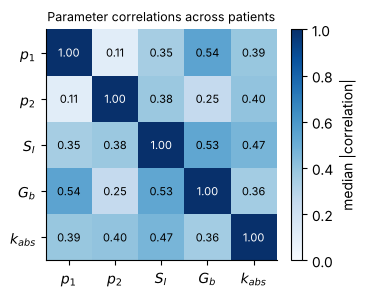

In [ ]:
# 1. multi-start spread
spread = {}
for j, pid in enumerate(pids):
    good = all_mse[:, j] <= 1.02 * all_mse[:, j].min()
    th = all_theta[good, j].numpy()
    spread[pid] = (th.std(0) / th.mean(0)) if good.sum() > 1 else np.full(5, np.nan)
spread = pd.DataFrame(spread, index=NAMES).T

# 2. local sensitivity matrix by central differences in log-parameter space
def jacobian_patient(j, h=1e-3):
    w = train_all[train_all["pid"] == pids[j]].reset_index(drop=True)
    B = build_batch(w, patients, I_1min)
    base = torch.log(theta_mech[j])
    cols = []
    for k in range(5):
        out = []
        for sgn in (1, -1):
            lt = base.clone(); lt[k] += sgn * h
            th = theta_mech.clone(); th[j] = torch.exp(lt)
            with torch.no_grad():
                out.append(simulate(th, B)[B["M"]])
        cols.append((out[0] - out[1]) / (2 * h))
    with torch.no_grad():
        res = (simulate(theta_mech, B) - B["G"])[B["M"]]
    return torch.stack(cols, 1).numpy(), float((res ** 2).mean())

corrs, rse = [], {}
for j, pid in enumerate(pids):
    J, s2 = jacobian_patient(j)
    cov = s2 * np.linalg.pinv(J.T @ J)
    sd = np.sqrt(np.diag(cov))
    corrs.append(cov / np.outer(sd, sd))
    rse[pid] = sd
rse = pd.DataFrame(rse, index=NAMES).T
med_corr = np.median(np.abs(np.array(corrs)), axis=0)

ident = pd.DataFrame({"multi-start CV (median)": spread.median(), "relative SE (median)": rse.median()}).round(2)
ident.to_csv(PROC / "identifiability.csv")

fig, ax = plt.subplots(figsize=(3.6, 3.0))
im = ax.imshow(med_corr, cmap="Blues", vmin=0, vmax=1)
labels = ["$p_1$", "$p_2$", "$S_I$", "$G_b$", "$k_{abs}$"]
ax.set_xticks(range(5)); ax.set_yticks(range(5)); ax.set_xticklabels(labels); ax.set_yticklabels(labels)
for a in range(5):
    for b in range(5):
        ax.text(b, a, f"{med_corr[a, b]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if med_corr[a, b] > 0.6 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, label="median |correlation|")
ax.set_title("Parameter correlations across patients", fontsize=9)
save_fig(fig, "identifiability_corr")
ident

<div style="background:#eaf3e6;border-left:6px solid #548235;padding:10px 14px;border-radius:4px">

**Interpretation — identifiability**

Multi-start fits agree closely (median spread 3–11 %), so the optimiser finds the same minimum. But the local analysis shows that $p_2$ (speed of insulin action, relative SE ≈ 67 %), $p_1$ (≈ 49 %) and $G_b$ (≈ 44 %) are poorly determined by free-living CGM data, and $p_1$, $S_I$ and $G_b$ are correlated (they can partly compensate for each other). $S_I$ and $k_{abs}$ are the best determined. Fitted values should therefore be read as *effective* parameters, not clinical measurements.

</div>

## 5. Mathematical analysis: equilibrium, stability and numerical convergence

<div style="background:linear-gradient(90deg,#1f4e79,#2e75b6);color:white;padding:10px 14px;border-radius:6px;font-size:1.25em;font-weight:600">5. Mathematical analysis: equilibrium, stability and numerical convergence</div>

### 5.1 Equilibrium under constant basal insulin
With no meal and a constant basal infusion $u_b$ (mU/min), setting all derivatives to zero gives, in order,
$$S_1^* = S_2^* = \frac{u_b}{k_d},\quad I^* = \frac{u_b}{k_e V_I BW},\quad X^* = S_I I^*,\quad Q_1^*=Q_2^*=0,\quad G^* = \frac{p_1 G_b}{p_1 + S_I I^*}.$$
So the fasting glucose a patient settles at falls as basal insulin or insulin sensitivity rise — this is exactly the formula a clinician's basal-rate adjustment works through.

### 5.2 Local stability
Order the state as $(S_1, S_2, I, Q_1, Q_2, X, G)$. Insulin and gut do not depend on $X$ or $G$, and $X$ does not depend on $G$, so the Jacobian at the equilibrium is **lower block-triangular**; its eigenvalues are the diagonal entries:
$$\lambda \in \{-k_d,\ -k_d,\ -k_e,\ -k_{abs},\ -k_{abs},\ -p_2,\ -(p_1 + X^*)\}.$$
All are real and negative for any positive parameters, so the equilibrium is a **locally asymptotically stable node**: no oscillations, and the slowest return rate is $\min(p_2, p_1 + X^*, k_{abs})$. We confirm this numerically below by computing the Jacobian with automatic differentiation for every fitted patient.

### 5.3 Convergence of the numerical scheme
The forecasts use explicit Euler with $\Delta t = 1$ min. We compare against a high-accuracy reference (`scipy` RK45, tolerance $10^{-10}$) for a 50 g meal with a 5 U bolus, for a reference patient (the one whose fasting equilibrium is closest to 120 mg/dL). Euler is first-order, so the error should fall in proportion to $\Delta t$.

In [ ]:
from scipy.integrate import solve_ivp

def rhs(y, th, u_b):
    """Full model right-hand side, state y = (S1, S2, I, Q1, Q2, X, G). Works for numpy or torch."""
    S1, S2, I, Q1, Q2, X, G = y
    p1, p2, SI, Gb, kabs = th
    return [u_b - KD * S1, KD * (S1 - S2), KD * S2 / (VI * BW) - KE * I,
            -kabs * Q1, kabs * (Q1 - Q2), -p2 * X + p2 * SI * I,
            -p1 * (G - Gb) - X * G + F * kabs * Q2 / (BW * VG)]

def equilibrium(th, u_b):
    p1, p2, SI, Gb, kabs = th
    I = u_b / (KE * VI * BW); X = SI * I
    return np.array([u_b / KD, u_b / KD, I, 0.0, 0.0, X, p1 * Gb / (p1 + X)])

stab = []
for j, pid in enumerate(pids):
    th = theta_mech[j].numpy()
    u_b = patients[pid]["basal_rate"].median() * 1000 / 5                 # mU/min
    y_eq = torch.tensor(equilibrium(th, u_b))
    Jac = torch.autograd.functional.jacobian(lambda y: torch.stack(rhs(y, torch.tensor(th), u_b)), y_eq).numpy()
    ev = np.linalg.eigvals(Jac)
    stab.append({"patient": pid, "basal (U/h)": round(u_b * 60 / 1000, 2), "I* (mU/L)": round(y_eq[2].item(), 1),
                 "G* (mg/dL)": round(y_eq[6].item()), "max Re(λ)": f"{ev.real.max():.4f}",
                 "all Re(λ)<0": bool((ev.real < 0).all()), "complex λ": bool(np.abs(ev.imag).max() > 1e-12)})
stab = pd.DataFrame(stab).set_index("patient")
stab.to_csv(PROC / "stability.csv")
stab

,basal (U/h),I* (mU/L),G* (mg/dL),max Re(λ),all Re(λ)<0,complex λ
patient,,,,,,
HUPA0001P,0.50,7.2,182,-0.0100,True,False
HUPA0002P,0.95,13.7,48,-0.0013,True,False
HUPA0003P,0.80,11.5,148,-0.0031,True,False
HUPA0004P,0.90,12.9,223,-0.0057,True,False
HUPA0005P,0.85,12.2,124,-0.0028,True,False
HUPA0006P,0.90,12.9,27,-0.0048,True,False
HUPA0007P,1.00,14.4,298,-0.0044,True,False
HUPA0016P,0.88,12.7,118,-0.0040,True,False
HUPA0017P,0.71,10.2,49,-0.0061,True,False


reference patient HUPA0016P: basal 0.88 U/h, G* = 118 mg/dL


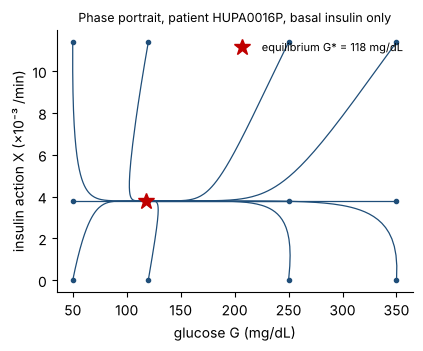

In [ ]:
# Reference patient for the illustrations below: the one whose fasting equilibrium G* is closest to 120 mg/dL.
REF = (stab["G* (mg/dL)"] - 120).abs().idxmin()
th_med = theta_mech[pids.index(REF)].numpy()
u_b = patients[REF]["basal_rate"].median() * 1000 / 5                      # mU/min
y_eq = equilibrium(th_med, u_b)
print(f"reference patient {REF}: basal {u_b * 60 / 1000:.2f} U/h, G* = {y_eq[6]:.0f} mg/dL")
fig, ax = plt.subplots(figsize=(4.6, 3.4))
for G0 in (50, 120, 250, 350):
    for Xf in (0.0, 1.0, 3.0):
        y0 = y_eq.copy(); y0[6] = G0; y0[5] = Xf * y_eq[5]
        sol = solve_ivp(lambda t, y: rhs(y, th_med, u_b), (0, 1500), y0, rtol=1e-8, max_step=5)
        ax.plot(sol.y[6], sol.y[5] * 1e3, color=C_MODEL, lw=0.9)
        ax.plot(G0, y0[5] * 1e3, "o", color=C_MODEL, ms=3)
ax.plot(y_eq[6], y_eq[5] * 1e3, "*", color=C_HYB, ms=12, label=f"equilibrium G* = {y_eq[6]:.0f} mg/dL")
ax.set_xlabel("glucose G (mg/dL)"); ax.set_ylabel("insulin action X (×10⁻³ /min)")
ax.legend(frameon=False, fontsize=8, loc="upper right"); ax.set_title(f"Phase portrait, patient {REF}, basal insulin only", fontsize=9)
save_fig(fig, "phase_portrait")

observed order of convergence: 1.19


,dt (min),|G error| at 4 h (mg/dL),ratio
0,8.00,0.1989,2.7722
1,4.00,0.0717,2.4157
2,2.00,0.0297,2.2174
3,1.00,0.0134,2.1114
4,0.50,0.0063,2.0565
5,0.25,0.0031,NaN


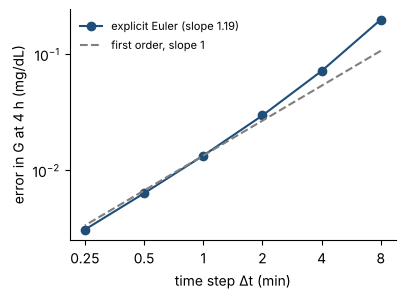

In [ ]:
def euler(th, u_b, y0, dt, T=240):
    y = np.array(y0, float)
    for _ in range(int(round(T / dt))):
        y = y + dt * np.array(rhs(y, th, u_b))
    return y

y0 = equilibrium(th_med, u_b).copy()
y0[3] = 50_000.0                         # 50 g meal into the stomach at t = 0
y0[0] += 5_000.0                         # 5 U bolus into the first subcutaneous compartment
ref = solve_ivp(lambda t, y: rhs(y, th_med, u_b), (0, 240), y0, method="RK45", rtol=1e-10, atol=1e-10).y[:, -1]
dts = [8, 4, 2, 1, 0.5, 0.25]
err = [abs(euler(th_med, u_b, y0, dt)[6] - ref[6]) for dt in dts]
order = np.polyfit(np.log(dts), np.log(err), 1)[0]
conv = pd.DataFrame({"dt (min)": dts, "|G error| at 4 h (mg/dL)": err})
conv["ratio"] = conv.iloc[:, 1] / conv.iloc[:, 1].shift(-1)

fig, ax = plt.subplots(figsize=(4.2, 3.0))
ax.loglog(dts, err, "o-", color=C_MODEL, label=f"explicit Euler (slope {order:.2f})")
ax.loglog(dts, err[3] * np.array(dts) / dts[3], "--", color=C_PERS, label="first order, slope 1")
ax.set_xticks(dts); ax.set_xticklabels([f"{d:g}" for d in dts]); ax.minorticks_off()
ax.set_xlabel("time step Δt (min)"); ax.set_ylabel("error in G at 4 h (mg/dL)")
ax.legend(frameon=False, fontsize=8)
save_fig(fig, "convergence")
print(f"observed order of convergence: {order:.2f}")
conv.round(4)

<div style="background:#eaf3e6;border-left:6px solid #548235;padding:10px 14px;border-radius:4px">

**Interpretation — stability and numerics**

Every one of the fitted patients has a unique, stable, non-oscillating fasting equilibrium, as the triangular-Jacobian argument predicts. The phase portrait shows the two time-scales: insulin action $X$ relaxes first, then glucose slides to $G^*$. Euler's error halves when Δt halves (ratio → 2, first order); at Δt = 1 min it is about 0.01 mg/dL, a thousand times smaller than sensor noise, so the 1-min Euler scheme is more than accurate enough.

</div>

## 6. Sensitivity analysis: which parameters drive the meal response?

<div style="background:linear-gradient(90deg,#1f4e79,#2e75b6);color:white;padding:10px 14px;border-radius:6px;font-size:1.25em;font-weight:600">6. Sensitivity analysis: which parameters drive the meal response?</div>

Scenario: the reference patient (Section 5) at equilibrium on their own basal rate, then a 50 g meal with a 5 U bolus at $t=0$.

**Local (normalised) sensitivity** of glucose to each parameter,
$$S_{\theta_i}(t) = \frac{\theta_i}{G(t)}\,\frac{\partial G(t)}{\partial \theta_i},$$
read as "% change in glucose per 1 % change in the parameter" (central finite differences).

**Global (Sobol) sensitivity.** All five parameters are varied together, each log-uniformly between half and double the reference patient's value (Saltelli scheme on a Sobol sequence, $N = 1024$, i.e. 12 288 simulations, run as one vectorised batch). The first-order index $S_1$ is the share of output variance explained by a parameter alone; the total index $S_T$ includes its interactions. Outputs: peak glucose, and glucose 2 h after the meal.

peak glucose        glucose at 2 h       
               S1     ST             S1     ST
p1          0.183  0.249          0.152  0.198
p2         -0.000  0.000          0.004  0.007
SI          0.314  0.356          0.394  0.461
Gb          0.363  0.453          0.297  0.372
kabs        0.042  0.054          0.060  0.060

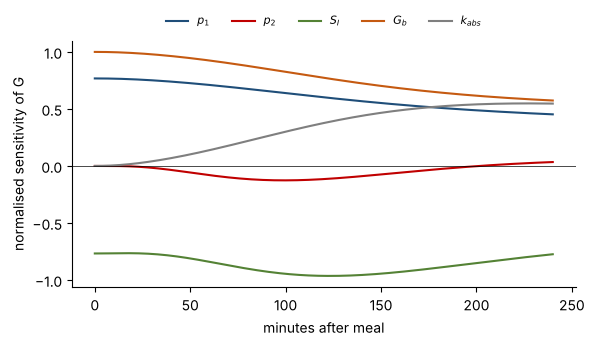

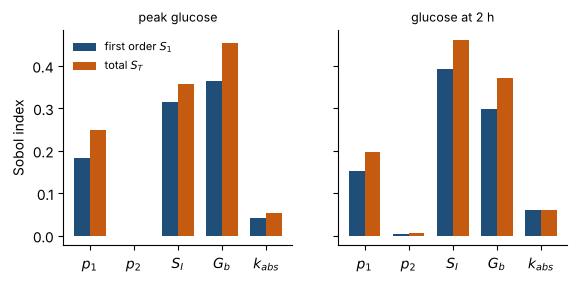

In [ ]:
from SALib.sample import sobol as sobol_sample
from SALib.analyze import sobol

def meal_response(TH, u_b=u_b, meal_g=50.0, bolus_U=5.0, T=240, dt=1.0):
    """Vectorised Euler simulation for many parameter sets TH (N, 5). Returns G (N, T/dt + 1)."""
    TH = np.atleast_2d(TH)
    th = tuple(TH[:, k] for k in range(5))
    y = np.stack([equilibrium(t, u_b) for t in TH], 1)        # (7, N)
    y[3] += meal_g * 1000; y[0] += bolus_U * 1000
    out = [y[6].copy()]
    for _ in range(int(T / dt)):
        y = y + dt * np.array(rhs(y, th, u_b)); out.append(y[6].copy())
    return np.array(out).T

t_axis = np.arange(241)
base_G = meal_response(th_med)[0]
fig, ax = plt.subplots()
colors = [C_MODEL, C_HYB, C_LSTM, C_MEAL, C_PERS]
for k, (lab, c) in enumerate(zip(["$p_1$", "$p_2$", "$S_I$", "$G_b$", "$k_{abs}$"], colors)):
    up, dn = th_med.copy(), th_med.copy(); up[k] *= 1.01; dn[k] /= 1.01
    S = (meal_response(up)[0] - meal_response(dn)[0]) / (2 * np.log(1.01)) / base_G
    ax.plot(t_axis, S, color=c, lw=1.5, label=lab)
ax.axhline(0, color="black", lw=0.5)
ax.set_xlabel("minutes after meal"); ax.set_ylabel("normalised sensitivity of G")
ax.legend(frameon=False, ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 1.15))
save_fig(fig, "local_sensitivity")

problem = {"num_vars": 5, "names": NAMES,
           "bounds": [[np.log(v / 2), np.log(v * 2)] for v in th_med]}
Xs = np.exp(sobol_sample.sample(problem, 1024, calc_second_order=False, seed=SEED))
Gs = meal_response(Xs)
outputs = {"peak glucose": Gs.max(1), "glucose at 2 h": Gs[:, 120]}
sob = {name: sobol.analyze(problem, y, calc_second_order=False, seed=SEED) for name, y in outputs.items()}
sobol_table = pd.concat({name: pd.DataFrame({"S1": s["S1"], "ST": s["ST"]}, index=NAMES) for name, s in sob.items()}, axis=1).round(3)
sobol_table.to_csv(PROC / "sobol_indices.csv")

fig, axes = plt.subplots(1, 2, figsize=(6.5, 2.8), sharey=True)
x = np.arange(5)
for a, (name, s) in zip(axes, sob.items()):
    a.bar(x - 0.18, s["S1"], 0.36, color=C_MODEL, label="first order $S_1$")
    a.bar(x + 0.18, s["ST"], 0.36, color=C_MEAL, label="total $S_T$")
    a.set_xticks(x); a.set_xticklabels(["$p_1$", "$p_2$", "$S_I$", "$G_b$", "$k_{abs}$"]); a.set_title(name, fontsize=9)
axes[0].set_ylabel("Sobol index"); axes[0].legend(frameon=False, fontsize=8)
save_fig(fig, "sobol")
sobol_table

<div style="background:#eaf3e6;border-left:6px solid #548235;padding:10px 14px;border-radius:4px">

**Interpretation — sensitivity**

For the reference patient the meal response is governed by $S_I$ and $G_b$ (together > 65 % of the variance), then $p_1$. $p_2$ has essentially no influence on peak or 2-h glucose — which is exactly why it is so poorly identifiable from data (Section 4.1): data cannot pin down a parameter the output does not depend on.

</div>

## 7. The hybrid model: a universal differential equation (UDE)

<div style="background:linear-gradient(90deg,#1f4e79,#2e75b6);color:white;padding:10px 14px;border-radius:6px;font-size:1.25em;font-weight:600">7. The hybrid model: a universal differential equation (UDE)</div>

**Why.** The fits above, and the sensitivity analysis, point at the gut: real meals raise glucose within 30–60 min and then fall, while the linear two-compartment gut with one rate $k_{abs}$ can only make one smooth, slow bump. Many patients' fitted $k_{abs}$ sit at the lower bound, i.e. the model "switches off" the meal rather than mis-time it. Real gastric emptying is known to be **nonlinear**: it slows down while the stomach is full and speeds up as it empties (Dalla Man et al., 2007).

**What we change.** We keep insulin kinetics, insulin action and the glucose equation exactly as before, and replace only the two gut transfer rates by neural networks of the compartment contents:
$$\frac{dQ_1}{dt} = D\,\delta(t-t_{meal}) - k_{abs}\,h_1(Q_1)\,Q_1,\qquad \frac{dQ_2}{dt} = k_{abs}\,h_1(Q_1)\,Q_1 - k_{abs}\,h_2(Q_2)\,Q_2,\qquad R_a = \frac{f\,k_{abs}\,h_2(Q_2)\,Q_2}{BW},$$
$$h_i(q) = \exp\!\big(\ln 5\cdot\tanh(\mathrm{NN}_i(q / 50\,\mathrm{g}))\big) \in [\tfrac15, 5].$$

Design choices, each for a reason:
* **Only the unknown part is learned.** The physiology we trust stays interpretable; the network has one input and ~300 weights per gate.
* **Mass conservation is built in**: every flux is (non-negative rate) × (content), so carbohydrate is never created or lost and contents never go negative.
* **Starts at the mechanistic model**: the network's last layer is initialised to zero, so $h_i \equiv 1$ at the start of training and the hybrid can only move away from the Bergman fit if the data support it.
* **Shared across patients**: $h_1, h_2$ are the same for everyone (how a stomach empties), while $(p_1, p_2, S_I, G_b, k_{abs})$ stay patient-specific.

**Training algorithm** (backpropagation through the ODE solver — "discretise-then-optimise"):
1. Initialise patient parameters at their Bergman fit and the network so that $h \equiv 1$.
2. For each iteration: simulate all training windows with Euler ($\Delta t$ = 1 min), compute the masked MSE, back-propagate through all 240 solver steps with PyTorch autograd, take one Adam step for network weights (learning rate $10^{-2}$) and patient parameters ($5\times 10^{-3}$); up to 600 iterations.
3. Every 10 iterations compute RMSE on a **validation set** (the last 20 % of each patient's training windows, in time); keep the weights with the best validation RMSE (early stopping).

In [ ]:
import copy

def train_hybrid(theta0, B_fit, B_val, iters=600, lr_nn=1e-2, lr_par=5e-3, gut=None, train_gut=True, seed=SEED, log=True):
    torch.manual_seed(seed)
    gut = Gut() if gut is None else gut
    z = from_params(theta0).clone().requires_grad_()
    groups = [{"params": [z], "lr": lr_par}]
    if train_gut:
        groups.append({"params": gut.parameters(), "lr": lr_nn})
    for p in gut.parameters():
        p.requires_grad_(train_gut)
    opt = torch.optim.Adam(groups)
    best = (np.inf, None, None); hist = []
    for it in range(iters + 1):
        if it % 10 == 0:
            with torch.no_grad():
                v = rmse(simulate(to_params(z), B_val, gut), B_val)
            hist.append((it, v))
            if v < best[0]:
                best = (v, z.detach().clone(), copy.deepcopy(gut.state_dict()))
        if it == iters:
            break
        opt.zero_grad()
        loss = masked_mse(simulate(to_params(z), B_fit, gut), B_fit)
        loss.backward(); opt.step()
    gut.load_state_dict(best[2])
    if log:
        print(f"best validation RMSE {best[0]:.2f} mg/dL at iteration {hist[int(np.argmin([h[1] for h in hist]))][0]}")
    return to_params(best[1]).detach(), gut, hist

def errors_by_horizon(pred, B):
    se = ((pred - B["G"]) ** 2 * B["M"]).sum(0) / B["M"].sum(0)
    ae = ((pred - B["G"]).abs() * B["M"]).sum(0) / B["M"].sum(0)
    return se.sqrt().detach().numpy(), ae.detach().numpy()

def persistence(B):
    return B["G0"].unsqueeze(1).repeat(1, WIN)

HORIZONS = {"30 min": 6, "1 h": 12, "2 h": 24, "4 h": 47}
def score_table(preds, B):
    rows = {}
    for name, p in preds.items():
        r, a = errors_by_horizon(p, B)
        row = {f"RMSE {h}": r[k] for h, k in HORIZONS.items()}
        row["RMSE all"] = float(masked_mse(p, B).sqrt()); row["MAE all"] = float((((p - B["G"]).abs() * B["M"]).sum() / B["M"].sum()))
        rows[name] = row
    return pd.DataFrame(rows).T.round(1)

## 8. Validation where the truth is known

<div style="background:linear-gradient(90deg,#1f4e79,#2e75b6);color:white;padding:10px 14px;border-radius:6px;font-size:1.25em;font-weight:600">8. Validation where the truth is known</div>

Real data never reveal the true rate at which a meal enters the blood, so we test the hybrid method in two controlled settings before using it on patients.

### 8.1 Twin experiment: is the hidden gut law recoverable?
We generate synthetic CGM data from **our own model** (same insulin inputs, meals, windows and fitted physiology as the real patients) but with a *nonlinear* stomach whose emptying saturates when full — Michaelis–Menten emptying, a classic description of gastric emptying (Lehmann & Deutsch, 1992):
$$\text{stomach} \to \text{gut flux} = \frac{V_{max}\,Q_1}{K_m + Q_1},\qquad V_{max} = 0.4\ \text{g/min},\ K_m = 10\ \text{g},\qquad \text{gut} \to \text{blood: } 0.05\,Q_2 ,$$
plus Gaussian sensor noise (SD 5 mg/dL). Everything except the gut is correctly specified, so this asks a clean question: **from glucose readings alone, can the network rediscover the hidden emptying law it was never told?** The linear Bergman gut cannot represent saturation.

In [ ]:
VMAX, KM, KABS_TRUE, NOISE = 400.0, 10_000.0, 0.05, 5.0          # mg/min, mg, 1/min, mg/dL

class TrueGut(nn.Module):
    """Hidden 'true' gut used only to generate the twin-experiment data."""
    def forward(self, q1, q2, kabs):
        return VMAX * q1 / (KM + q1), KABS_TRUE * q2

def make_twin(B, seed):
    g = torch.Generator().manual_seed(seed)
    with torch.no_grad():
        clean, ra = simulate(theta_mech, B, TrueGut(), return_ra=True)
    T = dict(B)
    T["G"] = clean + NOISE * torch.randn(clean.shape, generator=g)
    T["M"] = torch.ones_like(B["M"])
    T["ra_true"] = ra
    return T

Bt_fit, Bt_val, Bt_test = (make_twin(build_batch(sel(role=r), patients, I_1min), s) for s, r in enumerate(["fit", "val", "test"]))

path = MODEL / "twin_models.pt"
if RETRAIN or not path.exists():
    t0 = time.time()
    th_all, mse_all = fit_mechanistic(Bt_fit, len(pids), n_start=4)
    theta_tw_mech = th_all[mse_all.argmin(0), torch.arange(len(pids))]
    theta_tw_hyb, gut_twin, hist_tw = train_hybrid(theta_tw_mech, Bt_fit, Bt_val)
    torch.save({"mech": theta_tw_mech, "hyb": theta_tw_hyb, "gut": gut_twin.state_dict()}, path)
    print(f"trained in {time.time() - t0:.0f} s")
ck = torch.load(path)
theta_tw_mech, theta_tw_hyb = ck["mech"], ck["hyb"]
gut_twin = Gut(); gut_twin.load_state_dict(ck["gut"])

with torch.no_grad():
    pm_t, ra_m_t = simulate(theta_tw_mech, Bt_test, None, return_ra=True)
    ph_t, ra_h_t = simulate(theta_tw_hyb, Bt_test, gut_twin, return_ra=True)
twin_scores = score_table({"Persistence": persistence(Bt_test), "Bergman (mechanistic)": pm_t, "Hybrid UDE": ph_t}, Bt_test)
twin_scores.to_csv(PROC / "twin_scores.csv")
twin_scores

,RMSE 30 min,RMSE 1 h,RMSE 2 h,RMSE 4 h,RMSE all,MAE all
Persistence,33.5,67.4,102.4,111.8,90.0,73.0
Bergman (mechanistic),8.6,13.6,14.3,22.0,14.4,9.7
Hybrid UDE,5.1,5.9,5.4,7.5,6.1,4.6


{'Bergman (mechanistic)': '41% relative RMSE in R_a', 'Hybrid UDE': '7% relative RMSE in R_a'}


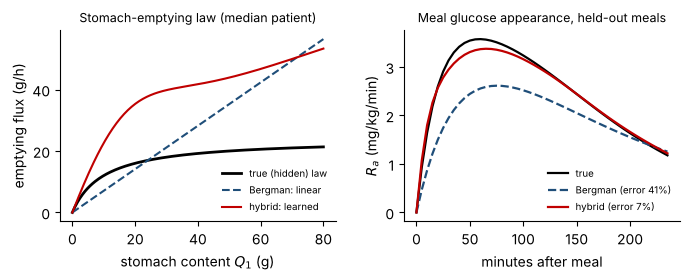

In [ ]:
# (a) learned vs true stomach-emptying flux, (b) rate of appearance after held-out meals
q = torch.linspace(0, 80_000, 200)
kabs_med = float(theta_tw_hyb[:, 4].median())
with torch.no_grad():
    flux_true = (VMAX * q / (KM + q)).numpy()
    flux_hyb = (theta_tw_hyb[:, 4].unsqueeze(1) * gut_twin.factor(gut_twin.h1, q).unsqueeze(0) * q).numpy()   # per patient
    flux_mech = (theta_tw_mech[:, 4].unsqueeze(1) * q).numpy()
single_t = sel(role="test").apply(lambda r: patients[r.pid]["carbs_g"].values[r.start + 1:r.start + WIN].sum() == 0, axis=1).values
ra_err = lambda ra: float(((ra - Bt_test["ra_true"])[single_t] ** 2).mean().sqrt() / Bt_test["ra_true"][single_t].mean())
twin_ra = {"Bergman (mechanistic)": ra_err(ra_m_t), "Hybrid UDE": ra_err(ra_h_t)}

fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.9))
ax = axes[0]
ax.plot(q / 1000, flux_true / 1000 * 60, color=C_OBS, lw=2, label="true (hidden) law")
ax.plot(q / 1000, np.median(flux_mech, 0) / 1000 * 60, color=C_MODEL, ls="--", lw=1.5, label="Bergman: linear")
ax.plot(q / 1000, np.median(flux_hyb, 0) / 1000 * 60, color=C_HYB, lw=1.5, label="hybrid: learned")
ax.set_xlabel("stomach content $Q_1$ (g)"); ax.set_ylabel("emptying flux (g/h)")
ax.set_title("Stomach-emptying law (median patient)", fontsize=9); ax.legend(frameon=False, fontsize=7)
ax = axes[1]
h_min = np.arange(WIN) * 5
for lab, ra, c, ls in [("true", Bt_test["ra_true"], C_OBS, "-"), ("Bergman", ra_m_t, C_MODEL, "--"), ("hybrid", ra_h_t, C_HYB, "-")]:
    ax.plot(h_min, ra[single_t].mean(0).numpy(), color=c, ls=ls, lw=1.6, label=f"{lab}" + ("" if lab == "true" else f" (error {100 * twin_ra['Bergman (mechanistic)' if lab == 'Bergman' else 'Hybrid UDE']:.0f}%)"))
ax.set_xlabel("minutes after meal"); ax.set_ylabel("$R_a$ (mg/kg/min)")
ax.set_title("Meal glucose appearance, held-out meals", fontsize=9); ax.legend(frameon=False, fontsize=7)
fig.tight_layout(); save_fig(fig, "twin_recovery")
print({k: f"{100 * v:.0f}% relative RMSE in R_a" for k, v in twin_ra.items()})

<div style="background:#eaf3e6;border-left:6px solid #548235;padding:10px 14px;border-radius:4px">

**Interpretation — twin experiment**

The hybrid model rediscovers the hidden gut law from glucose readings alone: its forecast RMSE on held-out meals falls from **14.4 to 6.1 mg/dL** (close to the 5 mg/dL sensor noise) and the error in the meal-appearance curve $R_a$ falls from **41 % to 7 %**. The *total* absorption is recovered; how it is split between the stomach and gut stages is not (left panel) — two stages in series can trade speed with each other and still give the same $R_a$. Only the composite is identifiable from glucose data.

</div>

### 8.2 Virtual patients from the UVA/Padova simulator: a realistic, misspecified test

Now the data come from a *different and richer* model than ours: **10 virtual adults** from the UVA/Padova Type 1 simulator (Dalla Man et al., 2007; Kovatchev et al., 2009; Python implementation `simglucose`, Xie 2018), whose gut has *nonlinear* gastric emptying and whose glucose–insulin system is much richer (13 states) than our model. Our model is now wrong about more than the gut — exactly as with real patients.

Data generation (`data/simulated/generate_simglucose.py`, run once): 14 days per patient; breakfast 40–70 g, lunch 60–90 g, dinner 50–90 g, a 15–30 g snack on 30 % of days; basal insulin at each patient's steady-state rate; a meal bolus = carbs / carb-ratio plus a correction above 150 mg/dL; CGM = true glucose + Gaussian noise (SD 5 mg/dL). The simulator also records the **true** $R_a(t)$.

Same pipeline as for real data: meal windows, first 70 % of days for fitting (last 20 % of those for validation), last 30 % for testing.

In [ ]:
sim_files = sorted(SIM.glob("SIM*.csv"))
sim_patients = {f.stem: load_patient(f) for f in sim_files}
sim_pids = sorted(sim_patients)
true_ra = {f.stem: pd.read_csv(f, sep=";")["true_ra"].values for f in sim_files}
I_sim = {pid: plasma_insulin_1min(sim_patients[pid]["insulin_U"].values) for pid in sim_pids}

rows = []
for pid in sim_pids:
    d = sim_patients[pid]; cut = int(TRAIN_FRAC * len(d))
    rows += [{"pid": pid, "start": i, "split": "train" if i < cut else "test"} for i in meal_windows(d)]
sim_windows = add_roles(pd.DataFrame(rows))
role = lambda r: sim_windows[sim_windows["role"] == r].reset_index(drop=True)
sim_fit_w, sim_val_w, sim_test_w = role("fit"), role("val"), role("test")
mk = lambda w: build_batch(w, sim_patients, I_sim, sim_pids)
Bs_fit, Bs_val, Bs_test = mk(sim_fit_w), mk(sim_val_w), mk(sim_test_w)
print(f"virtual patients: {len(sim_pids)}; windows: {len(sim_fit_w)} fit, {len(sim_val_w)} validation, {len(sim_test_w)} test")

path = MODEL / "sim_models.pt"
if RETRAIN or not path.exists():
    t0 = time.time()
    th_all, mse_all = fit_mechanistic(Bs_fit, len(sim_pids), n_start=4)
    theta_sim_mech = th_all[mse_all.argmin(0), torch.arange(len(sim_pids))]
    theta_sim_hyb, gut_sim, hist_sim = train_hybrid(theta_sim_mech, Bs_fit, Bs_val, iters=600)
    torch.save({"mech": theta_sim_mech, "hyb": theta_sim_hyb, "gut": gut_sim.state_dict(), "hist": hist_sim}, path)
    print(f"trained in {time.time() - t0:.0f} s")
ck = torch.load(path)
theta_sim_mech, theta_sim_hyb, hist_sim = ck["mech"], ck["hyb"], ck["hist"]
gut_sim = Gut(); gut_sim.load_state_dict(ck["gut"])

with torch.no_grad():
    pm_s, ra_m_s = simulate(theta_sim_mech, Bs_test, None, return_ra=True)
    ph_s, ra_h_s = simulate(theta_sim_hyb, Bs_test, gut_sim, return_ra=True)
sim_scores = score_table({"Persistence": persistence(Bs_test), "Bergman (mechanistic)": pm_s, "Hybrid UDE": ph_s}, Bs_test)
sim_scores.to_csv(PROC / "sim_scores.csv")
sim_scores

virtual patients: 10; windows: 236 fit, 63 validation, 134 test


,RMSE 30 min,RMSE 1 h,RMSE 2 h,RMSE 4 h,RMSE all,MAE all
Persistence,15.2,44.0,37.8,24.3,32.1,25.1
Bergman (mechanistic),14.9,13.9,9.8,11.3,10.9,8.0
Hybrid UDE,12.2,12.8,9.7,10.1,10.2,7.5


{'Bergman (mechanistic)': '46% relative profile error', 'Hybrid UDE': '47% relative profile error'} (111 single-meal windows)


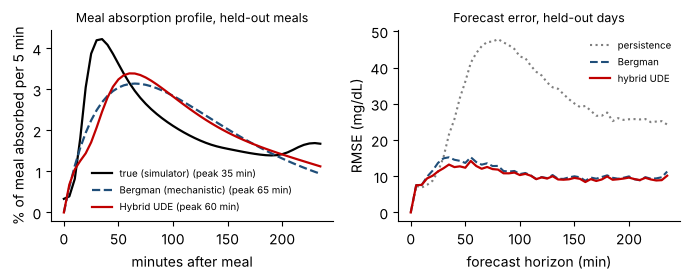

In [ ]:
# Recovery of the (normally unobservable) meal absorption curve on held-out meals
ra_true = np.array([true_ra[p][i:i + WIN] for p, i in zip(sim_test_w["pid"], sim_test_w["start"])])
first_meal_only = sim_test_w.apply(lambda r: sim_patients[r.pid]["carbs_g"].values[r.start + 1:r.start + WIN].sum() == 0, axis=1).values
norm = lambda a: a / a.sum(1, keepdims=True)                      # absorption *profile* (area 1): BW is unknown to our model
prof = {"true (simulator)": norm(ra_true[first_meal_only]),
        "Bergman (mechanistic)": norm(ra_m_s.numpy()[first_meal_only]),
        "Hybrid UDE": norm(ra_h_s.numpy()[first_meal_only])}
h_min = np.arange(WIN) * 5
peak = {k: h_min[v.mean(0).argmax()] for k, v in prof.items()}
prof_err = {k: np.sqrt(((v - prof["true (simulator)"]) ** 2).mean()) / prof["true (simulator)"].mean() for k, v in prof.items() if k != "true (simulator)"}

fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.9))
ax = axes[0]
for (k, v), c, ls in zip(prof.items(), [C_OBS, C_MODEL, C_HYB], ["-", "--", "-"]):
    ax.plot(h_min, v.mean(0) * 100, color=c, ls=ls, lw=1.6, label=f"{k} (peak {peak[k]} min)")
ax.set_xlabel("minutes after meal"); ax.set_ylabel("% of meal absorbed per 5 min")
ax.legend(frameon=False, fontsize=7); ax.set_title("Meal absorption profile, held-out meals", fontsize=9)
ax = axes[1]
r_m, _ = errors_by_horizon(pm_s, Bs_test); r_h, _ = errors_by_horizon(ph_s, Bs_test); r_p, _ = errors_by_horizon(persistence(Bs_test), Bs_test)
ax.plot(h_min, r_p, color=C_PERS, ls=":", lw=1.5, label="persistence")
ax.plot(h_min, r_m, color=C_MODEL, ls="--", lw=1.5, label="Bergman")
ax.plot(h_min, r_h, color=C_HYB, lw=1.6, label="hybrid UDE")
ax.set_xlabel("forecast horizon (min)"); ax.set_ylabel("RMSE (mg/dL)"); ax.legend(frameon=False, fontsize=7)
ax.set_title("Forecast error, held-out days", fontsize=9)
fig.tight_layout(); save_fig(fig, "sim_validation")
print({k: f"{100 * v:.0f}% relative profile error" for k, v in prof_err.items()}, f"({first_meal_only.sum()} single-meal windows)")

<div style="background:#eaf3e6;border-left:6px solid #548235;padding:10px 14px;border-radius:4px">

**Interpretation — UVA/Padova simulator**

Here the mechanistic model is already good (10.9 mg/dL) and the hybrid improves it modestly (10.2 mg/dL; 30-min error 14.9 → 12.2). But the learned absorption profile is **not** closer to the truth (46 % vs 47 % error): when other parts of the model are also wrong (insulin kinetics, glucose kinetics), the network improves the forecast by *compensating* for them. Better prediction does not imply a recovered mechanism — an important caution for interpreting the network on real patients.

</div>

## 9. The hybrid model on real patients

<div style="background:linear-gradient(90deg,#1f4e79,#2e75b6);color:white;padding:10px 14px;border-radius:6px;font-size:1.25em;font-weight:600">9. The hybrid model on real patients</div>

1. **Seen patients (11):** network + their parameters trained on their fitting windows, early stopping on their validation windows.
2. **Unseen patients (4):** the network is **frozen**; only their own five physiological parameters are fitted on their first 70 % of days (personalisation). Then both groups are tested on their last 30 % of days.

The mechanistic Bergman model uses exactly the same information (each patient's own first 70 % of days), so the comparison is fair.

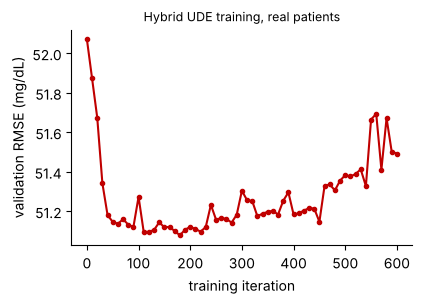

In [ ]:
seen_fit_w, seen_val_w = sel(group="seen", role="fit"), sel(group="seen", role="val")
uns_fit_w,  uns_val_w  = sel(group="unseen", role="fit"), sel(group="unseen", role="val")
mkr = lambda w: build_batch(w, patients, I_1min)
B_fit, B_val, B_ufit, B_uval = mkr(seen_fit_w), mkr(seen_val_w), mkr(uns_fit_w), mkr(uns_val_w)
B_seen_test, B_uns_test = mkr(sel(group="seen", split="test")), mkr(sel(group="unseen", split="test"))

path = MODEL / "hybrid_real.pt"
if RETRAIN or not path.exists():
    t0 = time.time()
    theta_h, gut_real, hist_real = train_hybrid(theta_mech, B_fit, B_val, iters=600)
    theta_hyb, _, _ = train_hybrid(theta_h, B_ufit, B_uval, gut=gut_real, train_gut=False, iters=200)   # personalise unseen
    torch.save({"theta": theta_hyb, "gut": gut_real.state_dict(), "hist": hist_real}, path)
    print(f"trained in {time.time() - t0:.0f} s")
ck = torch.load(path)
theta_hyb, hist_real = ck["theta"], ck["hist"]
gut_real = Gut(); gut_real.load_state_dict(ck["gut"])

fig, ax = plt.subplots(figsize=(4.4, 2.8))
ax.plot(*zip(*hist_real), "o-", color=C_HYB, ms=3)
ax.set_xlabel("training iteration"); ax.set_ylabel("validation RMSE (mg/dL)")
ax.set_title("Hybrid UDE training, real patients", fontsize=9)
save_fig(fig, "training_curve")

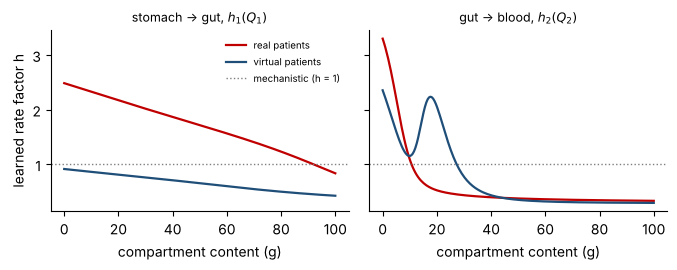

In [ ]:
# What did the networks learn? Speed-up factor of each gut transfer vs compartment content
q = torch.linspace(0, 100_000, 200)
with torch.no_grad():
    curves = {name: (g.factor(g.h1, q).numpy(), g.factor(g.h2, q).numpy()) for name, g in [("real patients", gut_real), ("virtual patients", gut_sim)]}
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.8), sharey=True)
for a, k, title in zip(axes, (0, 1), ("stomach → gut, $h_1(Q_1)$", "gut → blood, $h_2(Q_2)$")):
    for (name, cv), c in zip(curves.items(), (C_HYB, C_MODEL)):
        a.plot(q.numpy() / 1000, cv[k], color=c, lw=1.6, label=name)
    a.axhline(1, color=C_PERS, ls=":", lw=1, label="mechanistic (h = 1)")
    a.set_xlabel("compartment content (g)"); a.set_title(title, fontsize=9)
axes[0].set_ylabel("learned rate factor h"); axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout(); save_fig(fig, "learned_gut")

## 10. Pure machine-learning baseline: LSTM

<div style="background:linear-gradient(90deg,#1f4e79,#2e75b6);color:white;padding:10px 14px;border-radius:6px;font-size:1.25em;font-weight:600">10. Pure machine-learning baseline: LSTM</div>

Does the physics help at all? We compare against a model with **no physiology**: a 2-layer LSTM (64 units) that reads the last 2 h of glucose, insulin and carbs plus the insulin and carbs logged during the forecast window, and outputs the 4-h glucose trajectory (as a change from the current value). It is given *more* glucose information than the ODE models (2 h of history instead of only the current value). Trained on the same seen-patient fitting windows, Adam, weight decay $10^{-4}$, dropout 0.2, early stopping on the same validation windows. It has ~51 000 weights, versus ~600 for the hybrid's networks.

In [ ]:
import torch.nn as nn
PAST = 24

def lstm_inputs(wins, data):
    Xs, Y, M = [], [], []
    steps = np.arange(PAST + WIN)
    for pid, i in zip(wins["pid"], wins["start"]):
        d = data[pid]; gl = d["glucose"].values; sl = slice(i - PAST, i + WIN)
        known = steps <= PAST
        g = np.where(known, (gl[sl] - gl[i]) / 50.0, 0.0)
        Xs.append(np.stack([g, known.astype(float), d["insulin_U"].values[sl], d["carbs_g"].values[sl] / 50.0,
                            np.full(PAST + WIN, gl[i] / 100.0)], -1))
        Y.append(gl[i:i + WIN]); M.append(d["valid"].values[i:i + WIN])
    return torch.tensor(np.nan_to_num(np.array(Xs))), torch.tensor(np.nan_to_num(np.array(Y))), torch.tensor(np.array(M))

class LSTMForecaster(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(5, hidden, num_layers=2, batch_first=True, dropout=0.2)
        self.out = nn.Linear(hidden, 1)
    def forward(self, x):
        h, _ = self.lstm(x)
        return self.out(h[:, PAST:, :]).squeeze(-1) * 50.0          # change from current glucose, mg/dL

def lstm_predict(model, X, Y):
    model.eval()
    with torch.no_grad():
        return model(X) + Y[:, :1]

Lfit, Lval = lstm_inputs(seen_fit_w, patients), lstm_inputs(seen_val_w, patients)
lstm = LSTMForecaster()
path = MODEL / "lstm.pt"
if RETRAIN or not path.exists():
    torch.manual_seed(SEED)
    opt = torch.optim.Adam(lstm.parameters(), lr=2e-3, weight_decay=1e-4)
    best = (np.inf, None)
    Xf, Yf, Mf = Lfit
    for ep in range(200):
        lstm.train()
        for b in torch.randperm(len(Xf)).split(32):
            opt.zero_grad()
            pred = lstm(Xf[b]) + Yf[b, :1]
            (((pred - Yf[b]) ** 2 * Mf[b]).sum() / Mf[b].sum()).backward(); opt.step()
        if ep % 5 == 0:
            p = lstm_predict(lstm, Lval[0], Lval[1])
            v = float((((p - Lval[1]) ** 2 * Lval[2]).sum() / Lval[2].sum()).sqrt())
            if v < best[0]:
                best = (v, copy.deepcopy(lstm.state_dict()))
    torch.save(best[1], path)
    print(f"best validation RMSE {best[0]:.1f}")
lstm.load_state_dict(torch.load(path))
print("LSTM weights:", sum(p.numel() for p in lstm.parameters()), "| hybrid network weights:", sum(p.numel() for p in gut_real.parameters()))

LSTM weights: 51521 | hybrid network weights: 642


## 11. Results on held-out real data

<div style="background:linear-gradient(90deg,#1f4e79,#2e75b6);color:white;padding:10px 14px;border-radius:6px;font-size:1.25em;font-weight:600">11. Results on held-out real data</div>

All four forecasters see the same held-out meals (last 30 % of each patient's days, never used for fitting or early stopping). Errors use valid CGM readings only.

* **Persistence**: glucose stays at its current value — the bar every forecaster must clear.
* **Bergman (mechanistic)**: Section 4 fit.
* **Hybrid UDE**: Section 9.
* **LSTM**: Section 10.

RMSE 30 min  RMSE 1 h  \
held-out days, seen patients   Persistence                   29.9      48.7   
                               Bergman (mechanistic)         28.1      45.0   
                               Hybrid UDE                    27.9      44.8   
                               LSTM                          33.7      49.7   
held-out days, unseen patients Persistence                   26.5      36.3   
                               Bergman (mechanistic)         42.7      53.2   
                               Hybrid UDE                    34.8      46.0   
                               LSTM                          22.5      30.3   

                                                      RMSE 2 h  RMSE 4 h  \
held-out days, seen patients   Persistence                55.6      52.9   
                               Bergman (mechanistic)      46.8      45.5   
                               Hybrid UDE                 46.0      43.0   
                               LSTM                       55.2      47.6   
held-out days, unseen patients Persistence                69.6      86.9   
                               Bergman (mechanistic)      73.3      66.4   
                               Hybrid UDE                 68.4      62.9   
                               LSTM                       62.1      83.3   

                                                      RMSE all  MAE all  
held-out days, seen patients   Persistence                49.8     36.6  
                               Bergman (mechanistic)      43.1     32.7  
                               Hybrid UDE                 42.7     32.3  
                               LSTM                       48.5     37.0  
held-out days, unseen patients Persistence                61.6     44.5  
                               Bergman (mechanistic)      61.2     45.3  
                               Hybrid UDE                 56.2     42.5  
                               LSTM                       56.4     41.3

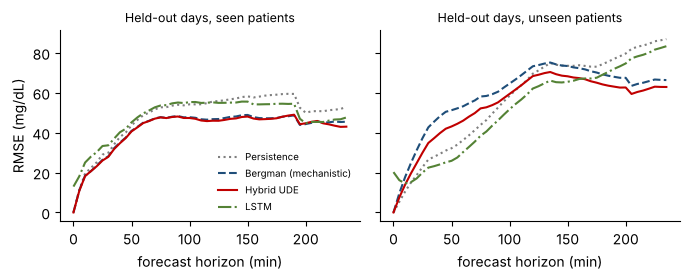

In [ ]:
def all_preds(B, wins):
    with torch.no_grad():
        Xl, Yl, _ = lstm_inputs(wins, patients)
        return {"Persistence": persistence(B), "Bergman (mechanistic)": simulate(theta_mech, B),
                "Hybrid UDE": simulate(theta_hyb, B, gut_real), "LSTM": lstm_predict(lstm, Xl, Yl)}

P_seen = all_preds(B_seen_test, sel(group="seen", split="test"))
P_uns  = all_preds(B_uns_test,  sel(group="unseen", split="test"))
results = pd.concat({"held-out days, seen patients": score_table(P_seen, B_seen_test),
                     "held-out days, unseen patients": score_table(P_uns, B_uns_test)})
results.to_csv(PROC / "results_real.csv")

fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.9), sharey=True)
styles = {"Persistence": (C_PERS, ":"), "Bergman (mechanistic)": (C_MODEL, "--"), "Hybrid UDE": (C_HYB, "-"), "LSTM": (C_LSTM, "-.")}
for a, (title, P, B) in zip(axes, [("seen patients", P_seen, B_seen_test), ("unseen patients", P_uns, B_uns_test)]):
    for name, p in P.items():
        a.plot(np.arange(WIN) * 5, errors_by_horizon(p, B)[0], color=styles[name][0], ls=styles[name][1], lw=1.5, label=name)
    a.set_title(f"Held-out days, {title}", fontsize=9); a.set_xlabel("forecast horizon (min)")
axes[0].set_ylabel("RMSE (mg/dL)"); axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout(); save_fig(fig, "rmse_horizon_real")
results

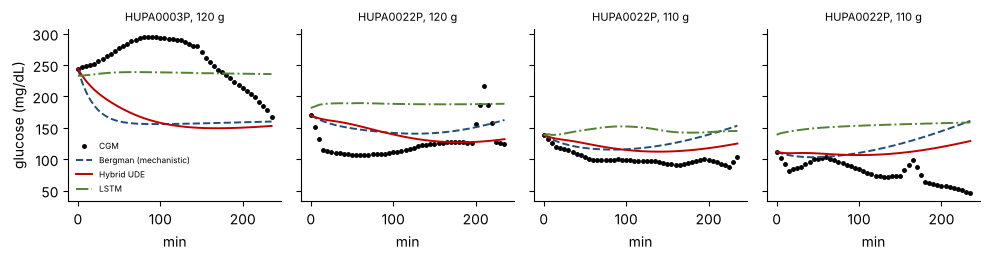

In [ ]:
# Four held-out meals (largest logged meals with no second meal in the window)
w = sel(group="seen", split="test")
single = w.apply(lambda r: patients[r.pid]["carbs_g"].values[r.start + 1:r.start + WIN].sum() == 0, axis=1).values
pick = np.argsort(-w["carbs_g"].values * single)[:4]
fig, axes = plt.subplots(1, 4, figsize=(10, 2.7), sharey=True)
h = np.arange(WIN) * 5
for a, j in zip(axes, pick):
    obs = np.where(B_seen_test["M"][j].numpy(), B_seen_test["G"][j].numpy(), np.nan)
    a.plot(h, obs, "o", ms=2.5, color=C_OBS, label="CGM")
    for name, p in P_seen.items():
        if name != "Persistence":
            a.plot(h, p[j].numpy(), color=styles[name][0], ls=styles[name][1], lw=1.4, label=name)
    a.set_title(f"{w['pid'].iat[j]}, {w['carbs_g'].iat[j]:.0f} g", fontsize=8); a.set_xlabel("min")
axes[0].set_ylabel("glucose (mg/dL)"); axes[0].legend(frameon=False, fontsize=6)
fig.tight_layout(); save_fig(fig, "example_forecasts")

<div style="background:#eaf3e6;border-left:6px solid #548235;padding:10px 14px;border-radius:4px">

**Interpretation — real patients**

On held-out days of patients seen in training, the two ODE models beat both baselines at every horizon: hybrid **42.7**, Bergman 43.1, LSTM 48.5, persistence 49.8 mg/dL (hybrid 14 % below persistence and 12 % below an LSTM with 80× more weights). On the four **unseen** patients the hybrid (56.2) improves on Bergman (61.2) by 8 % and ties the LSTM overall: the LSTM, which sees 2 h of glucose history, is best in the first hour, while the hybrid is far better at 4 h (62.9 vs 83.3), where physiology matters more than recent trend. All errors are large in absolute terms — see the limitations below.

</div>

## 12. Conclusions and limitations

<div style="background:linear-gradient(90deg,#1f4e79,#2e75b6);color:white;padding:10px 14px;border-radius:6px;font-size:1.25em;font-weight:600">12. Conclusions and limitations</div>

*(Numbers below refer to the tables printed above.)*

**What the mathematics tells us**
* Under constant basal insulin every fitted patient has a unique equilibrium $G^* = p_1 G_b/(p_1 + S_I I^*)$, and it is a stable node: the Jacobian is triangular with eigenvalues $-k_d, -k_d, -k_e, -k_{abs}, -k_{abs}, -p_2, -(p_1+X^*)$, all real and negative.
* Sobol analysis: the post-meal response is driven mainly by $S_I$ and $G_b$; $p_2$ has almost no influence — and identifiability analysis confirms $p_2$ is the least well determined parameter.
* Explicit Euler with Δt = 1 min is first-order convergent with error ≈ 0.01 mg/dL, far below sensor noise.

**What the data tell us**
* **Twin experiment:** the hybrid UDE recovers a hidden nonlinear gut law from glucose alone (meal-appearance error 41 % → 7 %; forecast RMSE 14.4 → 6.1 mg/dL).
* **UVA/Padova simulator:** forecasts improve modestly (10.9 → 10.2 mg/dL), but the learned absorption is not closer to the truth — under misspecification the network compensates rather than identifies.
* **Real patients:** physiology-based models beat persistence and an LSTM on held-out days (42.7 / 43.1 vs 48.5 / 49.8 mg/dL). On unseen patients the hybrid improves on Bergman by 8 % and ties the LSTM, winning clearly at 4 h.

**Limitations (and why the real-data errors are large)**
* **Unlogged events.** About half the boluses have no logged meal nearby; snacks, exercise and stress are invisible to every model.
* **Carbohydrate counts** are patient estimates (typically ±20–50 % error), logged in 10 g portions by most patients.
* **The CGM is a 15-min sensor interpolated to 5 min**, measures interstitial (not blood) glucose with a 5–10 min lag; this lag is not modelled.
* **Body weight is unknown**; a fixed 70 kg is absorbed into $S_I$ and the meal scale, so fitted parameter values are not directly comparable with clinical studies. Several patients' fitted $k_{abs}$ sit at the bound and some equilibria ($G^*$) are unphysiological — another sign of weak identifiability from free-living data.
* **Small data:** 16 usable patients, ~300 training meals; the four unseen patients give only 30 test meals.

**Possible extensions:** model CGM sensor lag; estimate unlogged meals as latent inputs (e.g. with a Kalman/particle filter); learn a residual term for exercise using the heart-rate and step data already in the dataset.

## 13. References and acknowledgements
* Bergman R.N. et al. (1979). Quantitative estimation of insulin sensitivity. *Am. J. Physiol.* 236, E667–E677.
* Hovorka R. et al. (2004). Nonlinear model predictive control of glucose concentration in subjects with type 1 diabetes. *Physiol. Meas.* 25, 905–920.
* Dalla Man C., Rizza R.A., Cobelli C. (2007). Meal simulation model of the glucose-insulin system. *IEEE Trans. Biomed. Eng.* 54, 1740–1749.
* Kovatchev B.P. et al. (2009). In silico preclinical trials: a proof of concept in closed-loop control of type 1 diabetes. *J. Diabetes Sci. Technol.* 3, 44–55.
* Rackauckas C. et al. (2020). Universal differential equations for scientific machine learning. arXiv:2001.04385.
* Chen R.T.Q. et al. (2018). Neural ordinary differential equations. *NeurIPS*.
* Hidalgo J.I. et al. (2024). HUPA-UCM diabetes dataset. *Data in Brief* 55, 110559. Data: https://data.mendeley.com/datasets/3hbcscwz44/1
* Xie J. (2018). simglucose v0.2.1, a Type-1 diabetes simulator in Python. https://github.com/jxx123/simglucose
* Sobol' I.M. (2001); Saltelli A. (2002) — variance-based sensitivity analysis; implemented with SALib (Herman & Usher, 2017).

**AI tools used:** Claude (Anthropic) was used to suggest and compare project topics, find candidate datasets, help design the model structure and validation plan, and draft code and text, which the group reviewed, ran and edited. *(Edit this statement so it accurately describes how your group used AI — the course requires it to be exact.)*